Oskar Sagstuen Nysæther, oskarsn, oskarsn@stud.ntnu.no
Eirin Sofie Aspehjell Rishaug, esrishau, esrishau@stud.ntnu.no

# Introduction

When a customer cancels an order in an online store, the store has often already spent money on it: the order has been confirmed, items have been reserved or picked from the warehouse, and sometimes a courier has been booked. For stores that offer cash on delivery, a cancellation can even happen at the customer's door, after the full delivery cost has been paid. If the store could tell at the moment an order is placed which orders are likely to be cancelled, it could act early, for example by calling the customer to confirm, asking for prepayment, or delaying the dispatch of risky orders.

In this project we use a large public dataset with more than half a million order lines from a Pakistani e-commerce store in the period July 2016 to August 2018. We build models that estimate the probability that an order is cancelled, using only information that is known when the order is placed, and we test how well the models work on the latest months of the data, which are kept aside until the very end.

## Problem statement

**Can information that is available when an order is placed – payment method, order value, discount, the contents of the basket and the time of the order – be used to predict whether an order will be cancelled, and how well do logistic regression and random forest predict cancellations in the months after the period they were trained on?**

The problem is a binary classification problem. The target variable `Cancelled` is 1 if the order was cancelled and 0 if it was completed. We study three questions:

1. Which order characteristics are associated with a high risk of cancellation?
2. How well does a simple, interpretable model (logistic regression) predict cancellations compared to a more flexible model (random forest), and compared to a simple rule that only uses the payment method?
3. How well do the models hold up over time, i.e. when they are used on later months than the ones they were trained on?

The last question matters because a store would train the model on historical orders and use it on new orders. A model that only works on randomly chosen orders from the same period as the training data is of little practical use.

## Choice of methods

We use **logistic regression** and **random forest**.

**Logistic regression** is the standard method for a binary target variable. It models the probability of cancellation directly, it is fast to fit on several hundred thousand orders, and each coefficient can be interpreted as the effect of one variable on the odds of cancellation when the other variables are held constant. This makes it well suited to answer the first question above. Ordinary (multiple) linear regression is not suitable, because it can predict "probabilities" below 0 or above 1 and assumes a constant effect on the probability scale. The performance of the logistic regression is estimated with **5-fold cross-validation** on the development period.

**Random forest** is an ensemble of decision trees. It can capture non-linear relationships and interactions between variables (for example that a high order value matters more for one payment method than for another) without us having to specify them in advance. The price is that the model is harder to interpret. Comparing the two methods shows whether this extra flexibility gives better predictions on this dataset.

Both models are compared to a **baseline**: the cancelled share for each payment method in the development period. A model that cannot beat such a simple rule adds little value.

# Data


## Description of the dataset

The dataset is "Pakistan's Largest E-Commerce Dataset", published on Kaggle. Each row is one **order line**, i.e. one product in one order. An order with three different products therefore has three rows with the same order number (`increment_id`). After removing empty trailing columns and rows, the data has 584,524 order lines and 21 columns, covering orders from 1 July 2016 to 28 August 2018. Amounts are in Pakistani rupees (PKR).

| Variable | Description | Used in the analysis |
|---|---|---|
| `item_id` | Unique id of the order line | Counting lines per order |
| `status` | Status of the order (16 different values, e.g. `complete`, `received`, `canceled`, `order_refunded`) | Basis for the target variable |
| `created_at` | Date the order was placed | Time split, weekday and month |
| `sku` | Product code (about 85,000 different values) | No – too many levels |
| `price` | Unit price of the product | Order value and highest price |
| `qty_ordered` | Number of units on the line | Quantity |
| `grand_total` | Total amount of the order after discounts (same on all lines of an order, see the checks below) | Order value |
| `increment_id` | Order number | Groups lines into orders |
| `category_name_1` | Product category (15 categories and a missing value `\N`) | Main category of the order |
| `sales_commission_code` | Code for a sales agent, missing for most lines | No |
| `discount_amount` | Discount on the line | Discount share |
| `payment_method` | Payment method (18 different methods) | Payment group |
| `Working Date`, `Year`, `Month`, `M-Y`, `FY` | The order date in other formats | No – duplicates `created_at` |
| `BI Status`, `MV` | Bookkeeping columns from the original spreadsheet (`BI Status` contains spreadsheet errors such as `#REF!`, `MV` is the price stored as text) | No – unclear definition |
| `Customer Since`, `Customer ID` | Customer id and the month the customer was first seen | No (see further work) |

The cell below reads the data and shows the first rows.

In [1]:
import pandas as pd

df = pd.read_csv("Pakistan Largest Ecommerce Dataset.csv", low_memory=False)

# The file contains empty trailing columns and rows
df = df.dropna(axis=1, how="all").dropna(how="all")
print(df.shape)
df.head()


(584524, 21)


,item_id,status,created_at,sku,price,qty_ordered,grand_total,increment_id,category_name_1,sales_commission_code,...,payment_method,Working Date,BI Status,MV,Year,Month,Customer Since,M-Y,FY,Customer ID
0,211131.0,complete,7/1/2016,kreations_YI 06-L,1950.0,1.0,1950.0,100147443,Women's Fashion,\N,...,cod,7/1/2016,#REF!,"1,950",2016.0,7.0,2016-7,7-2016,FY17,1.0
1,211133.0,canceled,7/1/2016,kcc_Buy 2 Frey Air Freshener & Get 1 Kasual Bo...,240.0,1.0,240.0,100147444,Beauty & Grooming,\N,...,cod,7/1/2016,Gross,240,2016.0,7.0,2016-7,7-2016,FY17,2.0
2,211134.0,canceled,7/1/2016,Ego_UP0017-999-MR0,2450.0,1.0,2450.0,100147445,Women's Fashion,\N,...,cod,7/1/2016,Gross,"2,450",2016.0,7.0,2016-7,7-2016,FY17,3.0
3,211135.0,complete,7/1/2016,kcc_krone deal,360.0,1.0,60.0,100147446,Beauty & Grooming,R-FSD-52352,...,cod,7/1/2016,Net,360,2016.0,7.0,2016-7,7-2016,FY17,4.0
4,211136.0,order_refunded,7/1/2016,BK7010400AG,555.0,2.0,1110.0,100147447,Soghaat,\N,...,cod,7/1/2016,Valid,"1,110",2016.0,7.0,2016-7,7-2016,FY17,5.0


## Preprocessing

The preprocessing has five steps, each in its own cell below:

1. **Cleaning of names and types.** Column names are stripped of extra spaces, `created_at` is converted to a date, and the missing category `\N` is replaced by `Unknown`.
2. **Checks of the raw data.** Before anything is filtered, we check that the information we later take once per order really is the same on every line of the order, and we count possible data errors.
3. **Choice of orders and target variable.** We keep orders with a clear final outcome: completed (`complete` or `received`) or cancelled (`canceled`).
4. **Aggregation to one row per order.** The status is decided per order, not per product. If each line were an observation, orders with many products would count several times and lines from the same order could end up in both the training and the test data.
5. **Feature engineering, dummy coding and the time split.** Skewed amounts are log-transformed, categorical variables are dummy coded, and the last four months are set aside as a test set.

We also define a function that computes the evaluation metrics used throughout the report.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_validate
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score,
)

RANDOM_STATE = 42

In [3]:
df = df.rename(columns=lambda name: name.strip())
df["created_at"] = pd.to_datetime(df["created_at"], format="%m/%d/%Y")
df["category_name_1"] = df["category_name_1"].replace("\\N", np.nan).fillna("Unknown")


In [4]:
# Checks on the raw order lines before any filtering: is the order information the same on every line?
per_order = df.groupby("increment_id")
multi_line = per_order.size() > 1
print("Orders:", per_order.ngroups, " of which multi-line:", multi_line.sum())
print("Orders with more than one status:", (per_order["status"].nunique() > 1).sum())
print("Orders with more than one grand_total:", (per_order["grand_total"].nunique() > 1).sum())
print("Multi-line orders where the discount differs between lines:", (per_order["discount_amount"].nunique() > 1)[multi_line].sum())

# Possible data errors
print("Duplicated rows:", df.duplicated().sum())
print("Missing numeric values:", df[["price", "qty_ordered", "grand_total", "discount_amount"]].isna().sum().sum())
print("Lines with price <= 0:", (df["price"] <= 0).sum())
print("Lines with quantity <= 0:", (df["qty_ordered"] <= 0).sum())
print("Lines with negative grand_total:", (df["grand_total"] < 0).sum())
print("Lines with negative discount:", (df["discount_amount"] < 0).sum())

Orders: 408782  of which multi-line: 81854
Orders with more than one status: 0
Orders with more than one grand_total: 0
Multi-line orders where the discount differs between lines: 21509


Duplicated rows: 0
Missing numeric values: 0
Lines with price <= 0: 2232
Lines with quantity <= 0: 0
Lines with negative grand_total: 76
Lines with negative discount: 3


**Results of the checks.** No order has more than one status or more than one `grand_total`. The status is therefore decided per order, and `grand_total` is the same number repeated on every line, so it must be counted once per order (we take the first value). The discount, on the other hand, differs between the lines in 21,509 multi-line orders, so `discount_amount` belongs to the individual line and must be **summed** to get the discount of the order. This is confirmed after the aggregation below, where `grand_total` equals the summed line values minus the summed discounts for most orders.

There are no duplicated rows, no missing numeric values and no lines with zero or negative quantity. There are 2,232 lines with a price of zero or less, 76 lines with a negative `grand_total` and 3 lines with a negative discount. These are very few compared to the 584,524 lines, and we keep them, but they are counted again at order level before they are clipped (see below).

In [5]:
# Refunds happen after delivery and are a different outcome than a cancellation.
# From May 2018 "received" replaces "complete" (see the table), so both count as a completed order
OUTCOMES = {"complete": 0, "received": 0, "canceled": 1}

lines = df[df["status"].isin(OUTCOMES.keys())].copy()
lines["Cancelled"] = lines["status"].map(OUTCOMES)
print("Order lines:", len(lines))
pd.crosstab(df["created_at"].dt.to_period("M"), df["status"])[["complete", "received", "canceled"]]

Order lines: 512224


status,complete,received,canceled
created_at,,,
2016-07,5877,28,1445
2016-08,7497,19,1381
2016-09,8117,74,5492
2016-10,7561,67,3486
2016-11,37492,2424,24664
2016-12,8066,273,2796
2017-01,7600,507,3112
2017-02,6935,196,2595
2017-03,11406,482,5016


**Which orders are kept, and why.** The table shows the number of order lines per month for the three statuses we use. Up to April 2018, `complete` is the normal status for a finished order. From May 2018 it is almost gone (1,446 lines in May and fewer than 100 per month afterwards), while `received` jumps from a few thousand to 11,675 lines in May. The store has clearly switched from `complete` to `received` as the label for a finished order, so the two statuses are treated as the same outcome. Without this, the last four months could not be used.

The other statuses are left out:

* `order_refunded` and `refund` (67,579 lines) describe orders that were delivered and later returned. That is a different event from a cancellation, which happens before delivery, and mixing them would make the target variable unclear.
* The remaining statuses (`cod`, `paid`, `closed`, `pending`, `processing`, `holded`, `payment_review`, `fraud` and a few others, about 4,700 lines in total, plus 15 lines without a status) are intermediate states where the final outcome is unknown.

The results of the analysis therefore apply to orders that were either completed or cancelled. 512,224 order lines are kept.

In [6]:
# Status is set per order (all lines of an order share it), so each order is one observation
lines["line_value"] = lines["price"] * lines["qty_ordered"]
main_category = lines.sort_values("line_value").groupby("increment_id")["category_name_1"].last()

orders = lines.groupby("increment_id").agg(
    created_at=("created_at", "first"),
    payment_method=("payment_method", "first"),
    grand_total=("grand_total", "first"),
    gross_value=("line_value", "sum"),
    discount=("discount_amount", "sum"),
    items=("item_id", "size"),
    quantity=("qty_ordered", "sum"),
    categories=("category_name_1", "nunique"),
    max_price=("price", "max"),
    Cancelled=("Cancelled", "first"),
)
orders["main_category"] = main_category

print("Orders:", len(orders), "Cancelled share:", round(orders["Cancelled"].mean(), 3))


Orders: 353964 Cancelled share: 0.42


The 512,224 lines become **353,964 orders**, of which 42.0 % were cancelled. For each order we compute:

* `grand_total`: the amount of the order after discounts (taken once per order),
* `gross_value`: the sum of price × quantity over all lines, i.e. the value before discounts,
* `discount`: the summed discount of all lines,
* `items`, `quantity` and `categories`: the number of lines, units and different categories,
* `max_price`: the price of the most expensive product,
* `main_category`: the category of the line with the highest value.

These are all known when the order is placed.

In [7]:
# Orders affected by the clipping in the next cell
print("Orders with negative grand_total:", (orders["grand_total"] < 0).sum())
print("Orders with gross value <= 0:", (orders["gross_value"] <= 0).sum())
print("Orders with discount larger than gross value:", (orders["discount"] > orders["gross_value"]).sum())

# grand_total is the order total if it equals the summed line values minus the summed discounts
matches = (orders["grand_total"] - (orders["gross_value"] - orders["discount"])).abs() < 1
print("Orders where grand_total = gross value - discount (within 1 PKR):", f"{matches.mean():.1%}")

Orders with negative grand_total: 23
Orders with gross value <= 0: 554
Orders with discount larger than gross value: 1026
Orders where grand_total = gross value - discount (within 1 PKR): 82.1%


Only 23 orders have a negative `grand_total`, 554 have a gross value of zero or less, and 1,026 have a larger discount than gross value (for example free products paid with a voucher). Together they are well below 1 % of the orders. In the next cell, negative amounts are set to zero before the log transform (the logarithm is not defined for negative numbers) and the discount share is limited to between 0 and 1. Because so few orders are affected, this has very little influence on the results, but it should be kept in mind that these orders may contain registration errors.

`grand_total` equals gross value minus discount for about four out of five orders. The rest are probably orders where vouchers, shipping costs or store credit are included in `grand_total` but not in the line discounts. This supports that `grand_total` is the order total and that summing the line discounts is correct.

In [8]:
orders["log_grand_total"] = np.log1p(orders["grand_total"].clip(lower=0))
orders["log_gross_value"] = np.log1p(orders["gross_value"].clip(lower=0))
orders["log_max_price"] = np.log1p(orders["max_price"].clip(lower=0))
orders["log_quantity"] = np.log1p(orders["quantity"])
orders["discount_share"] = (orders["discount"] / orders["gross_value"].replace(0, np.nan)).fillna(0).clip(0, 1)
orders["weekday"] = orders["created_at"].dt.day_name()
orders["month"] = orders["created_at"].dt.month_name()

# The payment groups are chosen from the development period only
TEST_START = pd.Timestamp("2018-05-01")
TOP_PAYMENT_METHODS = orders.loc[orders["created_at"] < TEST_START, "payment_method"].value_counts().index[:8]
orders["payment_group"] = orders["payment_method"].where(orders["payment_method"].isin(TOP_PAYMENT_METHODS), "Other")

dummies = pd.get_dummies(
    orders[["payment_group", "main_category", "weekday", "month"]], drop_first=True, dtype=int
)
orders = pd.concat([orders, dummies], axis=1)

FEATURES = [
    "log_grand_total", "log_gross_value", "log_max_price", "discount_share",
    "items", "log_quantity", "categories",
] + list(dummies.columns)
TARGET = "Cancelled"

orders[FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
log_grand_total,353964.0,7.807086,1.915088,0.000000,6.740519,7.650169,9.336180,16.699641
log_gross_value,353964.0,7.978176,1.728784,0.000000,6.867974,7.804251,9.441452,16.699641
log_max_price,353964.0,7.710814,1.787193,0.000000,6.459904,7.313887,9.392745,13.828058
discount_share,353964.0,0.082386,0.151309,0.000000,0.000000,0.000000,0.133791,1.000000
items,353964.0,1.447108,1.314713,1.000000,1.000000,1.000000,1.000000,72.000000
log_quantity,353964.0,0.925259,0.418364,0.693147,0.693147,0.693147,1.098612,7.601402
categories,353964.0,1.123990,0.429331,1.000000,1.000000,1.000000,1.000000,10.000000
payment_group_Easypay_MA,353964.0,0.027466,0.163437,0.000000,0.000000,0.000000,0.000000,1.000000
payment_group_Other,353964.0,0.021824,0.146110,0.000000,0.000000,0.000000,0.000000,1.000000
payment_group_Payaxis,353964.0,0.182185,0.385998,0.000000,0.000000,0.000000,0.000000,1.000000


**Feature engineering.**

* Amounts are strongly right-skewed (a few orders are worth several hundred thousand rupees), so `grand_total`, `gross_value`, `max_price` and `quantity` are transformed with $\log(1 + x)$. This reduces the influence of extreme orders on the logistic regression.
* `discount_share` = discount / gross value measures how large a part of the order was discounted.
* `weekday` and `month` capture weekly and seasonal patterns, for example sales campaigns in November.
* Only the eight most common payment methods get their own group; the remaining ones (each with very few orders) are merged into `Other`. The eight groups are chosen from the **development period only**, so the test period does not influence which groups the model uses.
* Categorical variables are dummy coded with `drop_first=True`, so one level of each variable is the reference level (`Easypay` for payment group, `Appliances` for main category, `Friday` for weekday and `April` for month). Without this, the dummy columns would be perfectly collinear with the intercept.

The categories of weekday, month and product category are fixed, known lists, and no payment method or category appears only in the test period, so the dummy coding does not leak information from the test period. The table shows that all variables are now numeric and on reasonable scales.

In [9]:
# Final analysis dataset: one row per order (the dummy columns can be recreated from the categorical columns)
orders.drop(columns=dummies.columns).to_csv("analysis_dataset.csv")

The final analysis dataset with one row per order is exported to `analysis_dataset.csv`.

In [10]:
# The last months are set aside as a test set before any training and are only used for the final evaluation
development = orders[orders["created_at"] < TEST_START]
test = orders[orders["created_at"] >= TEST_START]

for name, part in [("Development", development), ("Test", test)]:
    print(
        f"{name:<12} {part['created_at'].min().date()} - {part['created_at'].max().date()}"
        f"  orders: {len(part):>7}  cancelled: {part[TARGET].mean():.1%}"
    )

Development  2016-07-01 - 2018-04-30  orders:  314225  cancelled: 40.4%
Test         2018-05-01 - 2018-08-28  orders:   39739  cancelled: 54.7%


**The time split.** The data is split in time, not at random:

* **Development period** (1 July 2016 – 30 April 2018, 314,225 orders): used for all training, cross-validation and choice of parameters.
* **Test period** (1 May 2018 – 28 August 2018, 39,739 orders): set aside before any model is trained and used **only once**, for the final evaluation.

This copies how the models would be used in practice: trained on the past and used on the future. Note already that the cancelled share is much higher in the test period (54.7 %) than in the development period (40.4 %). We return to the reason for this in the exploratory analysis and the error analysis.

In [11]:
def evaluate(actual, probability, threshold=0.5):
    predicted = (probability >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(actual, probability),
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted),
        "Recall": recall_score(actual, predicted),
    }


**Evaluation metrics.** An order is predicted as cancelled if the predicted probability is at least 0.5. With TP = correctly predicted cancellations, FP = completed orders predicted as cancelled, FN = cancellations predicted as completed, and TN = correctly predicted completed orders:

* **Accuracy** $= \frac{TP + TN}{TP + TN + FP + FN}$: the share of all orders that are classified correctly.
* **Precision** $= \frac{TP}{TP + FP}$: of the orders flagged as risky, the share that were actually cancelled. Low precision means many unnecessary follow-ups.
* **Recall** $= \frac{TP}{TP + FN}$: of the cancelled orders, the share the model finds.
* **ROC-AUC**: the probability that a randomly chosen cancelled order gets a higher predicted probability than a randomly chosen completed order. 0.5 is no better than chance and 1 is perfect ranking. ROC-AUC does not depend on the threshold of 0.5, so it is our main metric. This matters here because the cancelled share changes over time, and the best threshold changes with it.

## Exploratory data analysis

To avoid that knowledge of the test period influences our choices, plots that use the target variable only use the development period.

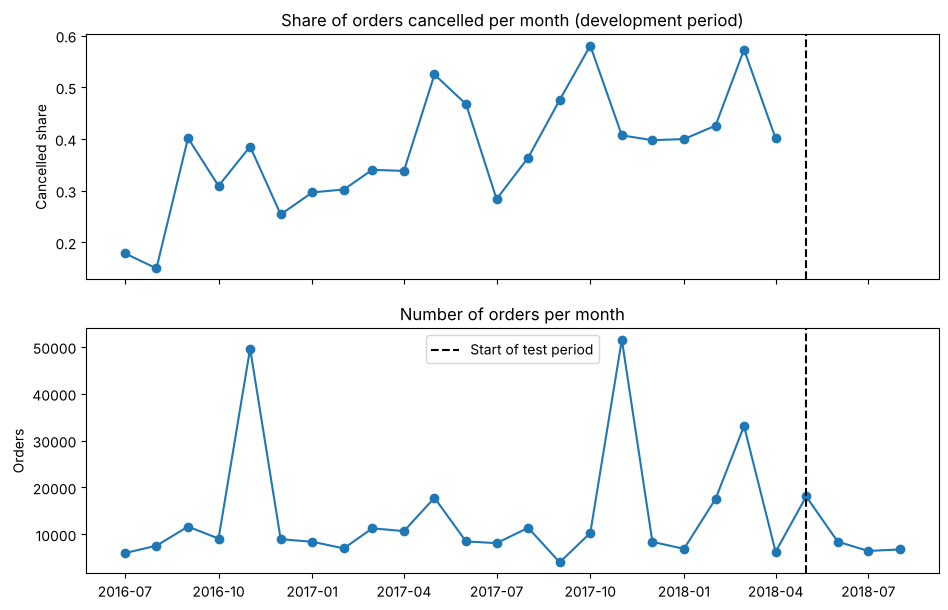

In [12]:
# Cancelled share per month (development period only, the test period is kept unseen) and orders per month
months = orders["created_at"].dt.to_period("M").dt.to_timestamp()
cancelled_share = development.groupby(months)[TARGET].mean()
order_count = orders.groupby(months).size()

fig, (share_ax, count_ax) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
share_ax.plot(cancelled_share.index, cancelled_share, marker="o")
share_ax.set(title="Share of orders cancelled per month (development period)", ylabel="Cancelled share")
count_ax.plot(order_count.index, order_count, marker="o")
count_ax.set(title="Number of orders per month", ylabel="Orders")
for ax in (share_ax, count_ax):
    ax.axvline(TEST_START, color="k", linestyle="--", label="Start of test period")
count_ax.legend()
plt.show()

**Over time.** The cancelled share varies a lot from month to month, from 15.0 % in August 2016 to 58.1 % in October 2017, and it rises over the development period. The number of orders has clear peaks in November 2016 and November 2017 (about 50,000 orders against a normal level of 5,000–15,000) and in March 2018. These peaks match large sales campaigns, which explains why `month` is included as a variable. The level and the pattern of cancellations are clearly not stable over time, which is a warning that a model trained on the past may work less well on the future.

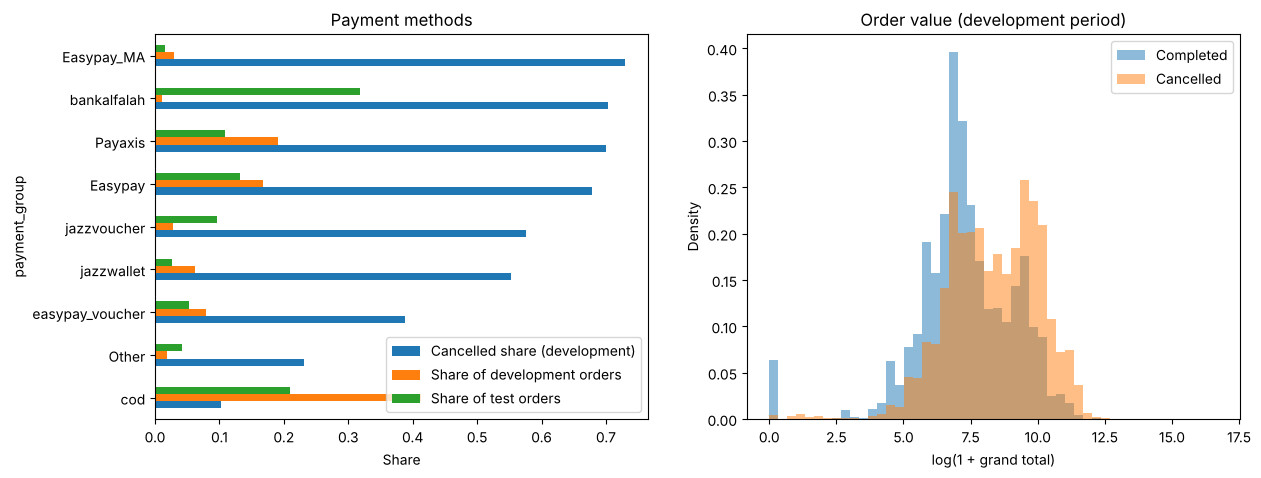

,Cancelled share (development),Share of development orders,Share of test orders
payment_group,,,
cod,0.102,0.413,0.209
Other,0.232,0.019,0.041
easypay_voucher,0.388,0.079,0.053
jazzwallet,0.552,0.063,0.026
jazzvoucher,0.576,0.027,0.095
Easypay,0.678,0.167,0.132
Payaxis,0.700,0.191,0.109
bankalfalah,0.703,0.011,0.318
Easypay_MA,0.729,0.029,0.016


In [13]:
fig, (payment_ax, value_ax) = plt.subplots(1, 2, figsize=(14, 5))

# Payment methods: cancelled share in the development period, and how common they are in each period
payment = pd.DataFrame({
    "Cancelled share (development)": development.groupby("payment_group")[TARGET].mean(),
    "Share of development orders": development["payment_group"].value_counts(normalize=True),
    "Share of test orders": test["payment_group"].value_counts(normalize=True),
}).sort_values("Cancelled share (development)")
payment.plot.barh(ax=payment_ax)
payment_ax.set(title="Payment methods", xlabel="Share")

# Order value for completed and cancelled orders
for outcome, label in [(0, "Completed"), (1, "Cancelled")]:
    values = development.loc[development[TARGET] == outcome, "log_grand_total"]
    value_ax.hist(values, bins=50, alpha=0.5, density=True, label=label)
value_ax.set(title="Order value (development period)", xlabel="log(1 + grand total)", ylabel="Density")
value_ax.legend()
plt.show()
payment.round(3)

**Payment method** is the variable with the clearest relationship to cancellation. Cash on delivery (`cod`) was used for 41.3 % of the orders in the development period, and only 10.2 % of these were cancelled. For the online payment methods, the cancelled share is between 39 % and 73 %. A likely explanation is that an online payment that is started but not completed (or fails) is registered as a cancelled order, while a COD order is only cancelled if the customer actively cancels or refuses delivery.

The mix of payment methods is very different in the test period. `bankalfalah` was used for only 1.1 % of the development orders, but for 31.8 % of the test orders, and it has one of the highest cancelled shares (70.3 %). At the same time, the share of COD orders falls from 41.3 % to 20.9 %. This shift alone explains much of the higher cancelled share in the test period.

**Order value.** Cancelled orders tend to be more expensive than completed orders. The distribution of cancelled orders has a clear second peak at high values (around $e^{10} \approx 22{,}000$ PKR), which fits with expensive products such as mobile phones. Completed orders also have a small group with an order value of zero, which are orders paid entirely with vouchers or store credit.

# Learning method 1: Logistic regression

## Basic principles

Logistic regression models the probability that order $i$ is cancelled as a function of its variables $x_{i1}, \dots, x_{ip}$:

$$
P(Y_i = 1 \mid x_i) = p_i = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_{i1} + \dots + \beta_p x_{ip})}}
$$

The logistic (sigmoid) function makes sure the prediction always lies between 0 and 1. Equivalently, the model is linear in the **log-odds**:

$$
\log \frac{p_i}{1 - p_i} = \beta_0 + \beta_1 x_{i1} + \dots + \beta_p x_{ip}
$$

A coefficient $\beta_j$ is therefore the change in the log-odds of cancellation when $x_j$ increases by one unit and the other variables are held constant, and $e^{\beta_j}$ is the factor the odds are multiplied by. Since all variables are standardised (mean 0 and standard deviation 1) before fitting, one unit is one standard deviation, which makes the coefficients comparable in size.

The coefficients are estimated by maximising the log-likelihood

$$
\ell(\beta) = \sum_{i=1}^{n} \big[ y_i \log p_i + (1 - y_i) \log(1 - p_i) \big].
$$

Scikit-learn by default adds an L2 penalty $\frac{1}{2C}\sum_j \beta_j^2$ with $C = 1$, which shrinks the coefficients slightly towards zero. With more than 300,000 orders, the penalty is very small compared to the log-likelihood and has little effect.

**K-fold cross-validation.** To estimate how well the model predicts orders it has not seen, the development data is split into $K = 5$ equally large parts (folds). The model is trained on four folds and evaluated on the fifth, and this is repeated so that each fold is used for evaluation once. The average of the five scores is the cross-validation estimate, and the standard deviation shows how much it varies between the folds. Because the folds are drawn at random, orders from the same months are found in both the training and the evaluation folds.

## Application and results

The model is a pipeline that first standardises all variables and then fits the logistic regression. Keeping the standardisation inside the pipeline means that in each cross-validation round, the mean and standard deviation are computed from the training folds only.

In [14]:
def make_logistic_model():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))


# 5-fold cross-validation on the development period: train on four folds and score on the fifth, five times
cv_scores = cross_validate(
    make_logistic_model(), development[FEATURES], development[TARGET],
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring=["roc_auc", "accuracy", "precision", "recall"],
)
cv_scores = pd.DataFrame(cv_scores).filter(like="test_")
cv_scores.agg(["mean", "std"]).T

,mean,std
test_roc_auc,0.848395,0.002271
test_accuracy,0.767297,0.002601
test_precision,0.695151,0.002263
test_recall,0.754849,0.003930


**Cross-validation results.** Across the five folds, the logistic regression has a mean ROC-AUC of **0.848**, accuracy of 76.7 %, precision of 69.5 % and recall of 75.5 %. The standard deviations are very small (about 0.002–0.004), so the result hardly depends on which orders end up in which fold. This is expected with more than 60,000 orders in each fold.

These numbers describe how well the model predicts randomly chosen orders **from the same period** as it was trained on. Because the folds are drawn at random, the model has seen orders from the same weeks, campaigns and payment mix as the ones it is evaluated on. As the comparison section shows, this gives a too optimistic picture of how well the model works on later months.

In [15]:
# Final model trained on the whole development period
logistic_model = make_logistic_model().fit(development[FEATURES], development[TARGET])
coefficients = pd.Series(logistic_model[-1].coef_[0], index=FEATURES)
coefficients.sort_values(key=abs, ascending=False).head(15)

payment_group_cod                 -1.572990
log_grand_total                    0.984522
log_gross_value                   -0.742448
discount_share                    -0.446002
payment_group_easypay_voucher     -0.333159
month_March                       -0.269923
month_February                    -0.218553
month_November                    -0.212821
payment_group_Other               -0.200343
main_category_Unknown              0.123521
main_category_Others               0.109951
month_December                    -0.101055
main_category_Mobiles & Tablets    0.085318
payment_group_Payaxis              0.079256
main_category_Superstore          -0.078098
dtype: float64

**Interpretation of the coefficients.** The final model is trained on the whole development period. The table shows the 15 largest coefficients in absolute value. Since the variables are standardised, each coefficient is the change in the log-odds of cancellation when the variable increases by one standard deviation, holding the other variables constant.

* **Cash on delivery** has by far the largest coefficient (−1.57). Compared to the reference group `Easypay`, COD orders have much lower odds of cancellation: one standard deviation increase in the COD dummy multiplies the odds by $e^{-1.57} \approx 0.21$. This matches the exploratory analysis.
* **Order value.** `log_grand_total` (+0.98) and `log_gross_value` (−0.74) have large coefficients with opposite signs. The two variables are strongly correlated, since both measure the size of the order, so they must be read together. If both increase by one standard deviation, the log-odds increase by about $0.98 - 0.74 = 0.24$: more expensive orders are cancelled more often. For a given gross value, a higher amount to pay (a smaller part covered by discounts or vouchers) increases the risk.
* **Discount share** (−0.45): orders with a larger discount are cancelled less often, which points the same way. Customers who have received a discount or used a voucher seem more committed to the purchase.
* **Payment by voucher** (`easypay_voucher`, −0.33) also has lower risk than `Easypay`.
* **Months.** February, March and November (−0.22, −0.27 and −0.21 compared to April) have lower odds of cancellation *when the other variables are held constant*. These months contain large campaigns, and the coefficients show the effect after the payment method and order value have been taken into account.
* **Product categories** have small coefficients (at most about 0.12), so the category adds little once payment method and value are known.

The coefficients describe associations, not causal effects. Because of the correlation between the value variables and the small L2 penalty, we do not interpret the exact size of each coefficient, and since scikit-learn does not give standard errors for a penalised model, we do not claim that individual coefficients are statistically significant.

In [16]:
logistic_probability = logistic_model.predict_proba(test[FEATURES])[:, 1]
print("Test:", evaluate(test[TARGET], logistic_probability))

Test: {'ROC-AUC': 0.7923696893658061, 'Accuracy': 0.7168776265129974, 'Precision': 0.6955388396514486, 'Recall': 0.8586401875603366}


**Results on the test period.** On the four test months, the logistic regression has a ROC-AUC of **0.792**, accuracy of 71.7 %, precision of 69.6 % and recall of 85.9 %. The AUC is 0.056 lower than in the cross-validation, which shows that the relationships in the data change over time. The model is still clearly better than chance (AUC 0.5). The accuracy of 71.7 % should be compared with 54.7 %, which is what we would get by predicting that all orders are cancelled.

Recall is higher and accuracy lower than in the cross-validation. With many more cancellations in the test period, and a payment mix shifted towards high-risk methods, the model predicts "cancelled" much more often, so it finds more of the cancellations but also flags more completed orders.

# Learning method 2: Random forest

## Basic principles

**Decision trees.** A classification tree splits the data step by step into smaller groups. At each step, the algorithm chooses the variable and threshold (for example "`payment_group_cod` = 1" or "`log_grand_total` > 8.5") that makes the two resulting groups as pure as possible. Purity is measured by the Gini impurity of a node with cancelled share $\hat p$:

$$
G = \sum_{k} \hat p_k (1 - \hat p_k) = 2 \hat p (1 - \hat p) \quad \text{(two classes)},
$$

and the split with the largest reduction in the weighted impurity of the two child nodes is chosen. The splitting stops when a node reaches the maximum depth (`max_depth`) or would get fewer orders than `min_samples_leaf`. The prediction for an order is the cancelled share in the leaf it ends up in. A single deep tree fits the training data very closely and has high variance: a small change in the data can give a very different tree.

**Random forest** reduces this variance by averaging many trees, and it has bootstrap built into the method:

1. Each of the $B$ trees is trained on its own **bootstrap sample**: $n$ orders drawn at random *with replacement* from the $n$ training orders.
2. At each split, only a random subset of $m$ of the $p$ variables is considered (in scikit-learn $m = \sqrt{p}$ for classification). This makes the trees less similar to each other, so the average reduces the variance more.
3. The predicted probability of cancellation is the average over the trees:
$$
\hat p(x) = \frac{1}{B} \sum_{b=1}^{B} \hat p_b(x).
$$

**Out-of-bag (OOB) evaluation.** The probability that a given order is not drawn in a bootstrap sample is $(1 - 1/n)^n \approx e^{-1} \approx 0.37$. Each order is therefore left out of about 37 % of the trees, and these trees can be used to predict it. Doing this for all orders gives the OOB score, a built-in estimate of performance on unseen orders that requires no separate validation data. Like random cross-validation, it uses orders from the same period as the training data.

**Feature importance** (mean decrease in impurity) adds up how much the splits on each variable reduce the Gini impurity, averaged over all trees. It shows which variables the forest uses most, but not the direction of the effect, and it tends to favour continuous variables that offer many possible split points.

## Application and results

Random forest does not need standardised variables, because the splits only depend on the order of the values. The same variables as in the logistic regression are used.

**Choice of parameters.** The most important parameters are the depth of the trees (`max_depth`) and the minimum number of orders in a leaf (`min_samples_leaf`). They are chosen within the development period, without using the test period. Instead of the OOB score, we train on the first year of the development period (July 2016 – June 2017) and evaluate on the remaining ten months (July 2017 – April 2018). This rewards parameter values that work on *later* months, which is what we want the model to do.

In [17]:
# Out-of-bag orders come from the same period as the training data, so they reward patterns that do not
# carry over in time. The parameters are therefore chosen by training on the first year of the development
# period and scoring on the last six months.
TUNING_SPLIT = pd.Timestamp("2017-07-01")
tuning_train = development[development["created_at"] < TUNING_SPLIT]
tuning_test = development[development["created_at"] >= TUNING_SPLIT]

PARAMETER_GRID = [
    {"max_depth": max_depth, "min_samples_leaf": min_samples_leaf}
    for max_depth in [6, 10, None]
    for min_samples_leaf in [20, 100, 500]
]

tuning_results = []
for parameters in PARAMETER_GRID:
    forest = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE, **parameters)
    forest.fit(tuning_train[FEATURES], tuning_train[TARGET])
    later_auc = roc_auc_score(tuning_test[TARGET], forest.predict_proba(tuning_test[FEATURES])[:, 1])
    tuning_results.append({**parameters, "later_period_AUC": later_auc})

tuning_results = pd.DataFrame(tuning_results).sort_values("later_period_AUC", ascending=False)
best = tuning_results.iloc[0]
best_parameters = {
    "max_depth": None if pd.isna(best["max_depth"]) else int(best["max_depth"]),
    "min_samples_leaf": int(best["min_samples_leaf"]),
}
print("Best parameters:", best_parameters)
tuning_results


Best parameters: {'max_depth': None, 'min_samples_leaf': 20}


,max_depth,min_samples_leaf,later_period_AUC
6,NaN,20,0.771085
7,NaN,100,0.755450
3,10.0,20,0.734450
8,NaN,500,0.731280
4,10.0,100,0.726861
5,10.0,500,0.721447
2,6.0,500,0.701645
0,6.0,20,0.701568
1,6.0,100,0.700007


**Results of the parameter search.** The best combination is unlimited depth with at least 20 orders per leaf, with an AUC of 0.771 on the later development months. Shallow trees (depth 6) give an AUC of only about 0.70, whatever the leaf size. Deep trees can describe combinations of variables, such as a high order value combined with a particular payment method, and these combinations seem to matter. Within each depth, small leaves are best, but the requirement of at least 20 orders per leaf still stops the trees from fitting single orders.

In [18]:
# Every tree is trained on its own bootstrap sample; the orders a tree never saw give the out-of-bag score
forest = RandomForestClassifier(
    n_estimators=300, oob_score=True, n_jobs=-1, random_state=RANDOM_STATE, **best_parameters
)
forest.fit(development[FEATURES], development[TARGET])
forest_out_of_bag_auc = roc_auc_score(development[TARGET], forest.oob_decision_function_[:, 1])
forest_probability = forest.predict_proba(test[FEATURES])[:, 1]

print("Out-of-bag AUC (development):", round(forest_out_of_bag_auc, 3))
print("Test:", evaluate(test[TARGET], forest_probability))


Out-of-bag AUC (development): 0.887
Test: {'ROC-AUC': 0.826598029434203, 'Accuracy': 0.7300888296132263, 'Precision': 0.694089484986095, 'Recall': 0.9064037144301935}


**Results.** The final forest has 300 trees and is trained on the whole development period with the chosen parameters.

* The **OOB AUC** on the development period is **0.887**, higher than the cross-validated AUC of the logistic regression (0.848).
* On the **test period**, the forest has a ROC-AUC of **0.827**, accuracy of 73.0 %, precision of 69.4 % and recall of 90.6 %.

The forest is better than the logistic regression on the test period (AUC 0.827 vs 0.792). The fall from the OOB score to the test score (0.061) is about the same as for the logistic regression, so the OOB score is just as optimistic as random cross-validation when the model is used on later months.

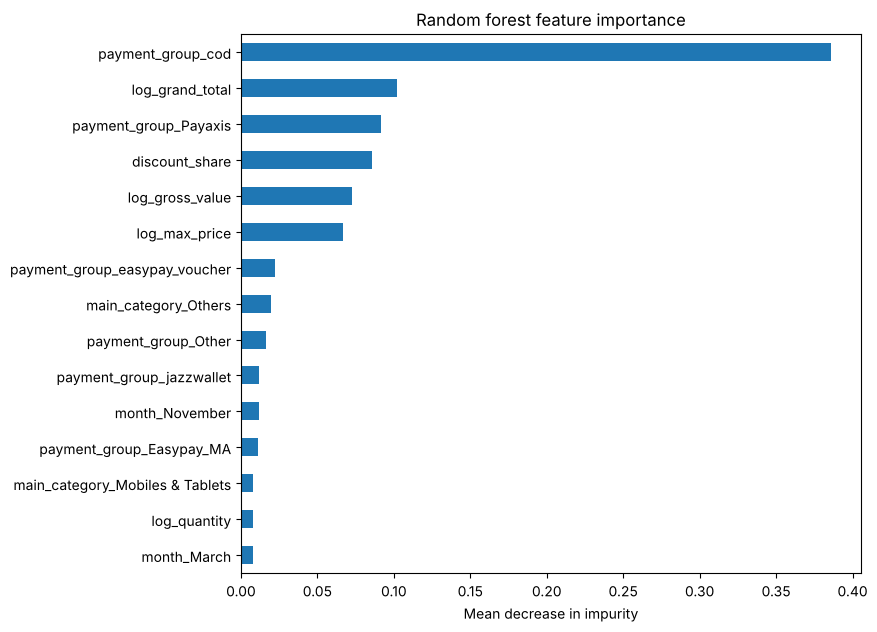

In [19]:
importances = pd.Series(forest.feature_importances_, index=FEATURES).sort_values().tail(15)

fig, ax = plt.subplots(figsize=(8, 7))
importances.plot.barh(ax=ax)
ax.set(title="Random forest feature importance", xlabel="Mean decrease in impurity")
plt.show()


**Feature importance.** The forest relies on the same information as the logistic regression. `payment_group_cod` is by far the most important variable (about 0.39 of the total impurity reduction), followed by order value (`log_grand_total`), the payment method `Payaxis`, the discount share, gross value and the highest price. Calendar and category variables are of minor importance. The continuous value variables may be somewhat overrated by this measure, since they offer many more split points than the dummy variables. The two methods thus tell the same story: **payment method first, then order value and discount**.

# Comparison and discussion

## Interpretation of the results

In this section the two methods are compared with each other and with the baseline, all on the same test period.

In [20]:
# Simple rule the models must beat: the cancelled share of each payment method in the development data
payment_cancellation_rate = development.groupby("payment_group")[TARGET].mean()
baseline_probability = (
    test["payment_group"].map(payment_cancellation_rate).fillna(development[TARGET].mean()).to_numpy()
)

probabilities = {
    "Baseline: payment method": baseline_probability,
    "Logistic regression": logistic_probability,
    "Random forest": forest_probability,
}
pd.DataFrame({name: evaluate(test[TARGET], p) for name, p in probabilities.items()}).T


,ROC-AUC,Accuracy,Precision,Recall
Baseline: payment method,0.749338,0.703641,0.680359,0.864984
Logistic regression,0.792370,0.716878,0.695539,0.858640
Random forest,0.826598,0.730089,0.694089,0.906404


**Comparison on the test period.**

| | ROC-AUC | Accuracy | Precision | Recall |
|---|---|---|---|---|
| Baseline: payment method | 0.749 | 70.4 % | 68.0 % | 86.5 % |
| Logistic regression | 0.792 | 71.7 % | 69.6 % | 85.9 % |
| Random forest | **0.827** | **73.0 %** | 69.4 % | **90.6 %** |

* The **baseline**, which only uses the payment method, already reaches an AUC of 0.749. This confirms that payment method carries most of the information.
* The **logistic regression** improves the AUC by 0.043 by adding order value, discount, basket contents and time.
* The **random forest** improves it by another 0.034, to 0.827, and has the highest accuracy and recall. Precision is almost the same for all three (68–70 %).

The forest is thus clearly the best model for *predicting* cancellations, while the logistic regression is easier to *explain*. With 39,739 orders in the test period, an AUC difference of 0.034 is large compared to the random variation we saw between the cross-validation folds (standard deviation about 0.002), so the difference is unlikely to be due to chance. We have, however, not tested it formally.

In [21]:
# Cross-validation folds and out-of-bag orders share the training period; the later development months and the test period lie in the future
logistic_later_model = make_logistic_model().fit(tuning_train[FEATURES], tuning_train[TARGET])
forest_later_model = RandomForestClassifier(
    n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE, **best_parameters
).fit(tuning_train[FEATURES], tuning_train[TARGET])

pd.DataFrame({
    "Development AUC (5-fold CV / out-of-bag)": [cv_scores["test_roc_auc"].mean(), forest_out_of_bag_auc],
    "Later development months AUC": [
        roc_auc_score(tuning_test[TARGET], logistic_later_model.predict_proba(tuning_test[FEATURES])[:, 1]),
        roc_auc_score(tuning_test[TARGET], forest_later_model.predict_proba(tuning_test[FEATURES])[:, 1]),
    ],
    "Test AUC": [roc_auc_score(test[TARGET], logistic_probability), roc_auc_score(test[TARGET], forest_probability)],
}, index=["Logistic regression", "Random forest"])

,Development AUC (5-fold CV / out-of-bag),Later development months AUC,Test AUC
Logistic regression,0.848395,0.771875,0.792370
Random forest,0.887437,0.771085,0.826598


**Performance over time.** The table shows the AUC of the two models at three distances in time from the training data:

* **Development AUC**: random folds (logistic regression) or out-of-bag orders (random forest) from the same period as the training data: 0.848 and 0.887.
* **Later development months**: trained on July 2016 – June 2017, evaluated on July 2017 – April 2018: 0.772 and 0.771.
* **Test AUC**: trained on the whole development period, evaluated on May – August 2018: 0.792 and 0.827.

Both models lose a lot of accuracy when they are used on later months, and the random forest loses most: from 0.887 to 0.771. Its flexibility lets it pick up patterns that are specific to the training period. When the models are only trained on the first year, the two are equally good on the later months. When they are trained on the full development period, the forest is clearly better on the test period. More data and data closer in time to the test period help the flexible model most.

The main lesson is that **random cross-validation and OOB scores overestimate how well the models will work in practice** when the data changes over time. The test AUC is the honest estimate.

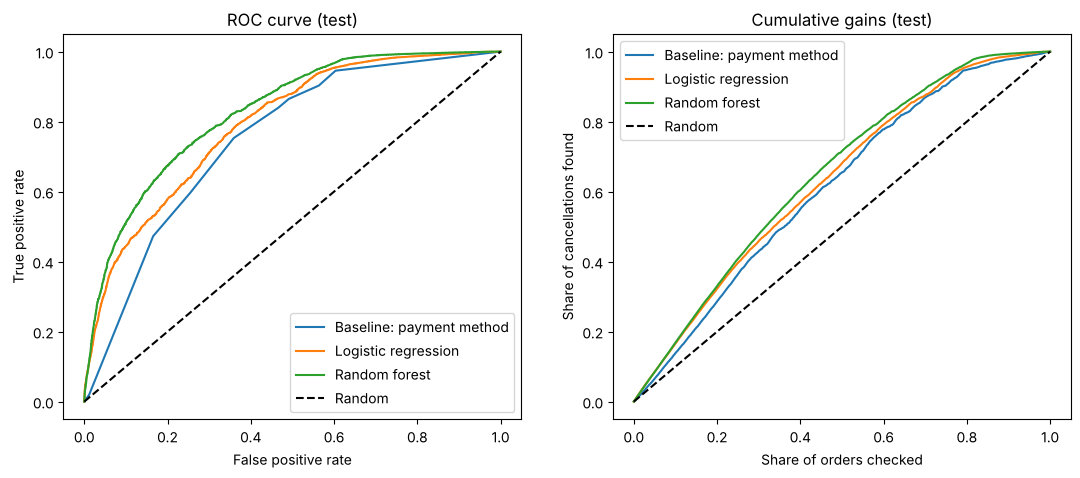

In [22]:
fig, (roc_ax, gains_ax) = plt.subplots(1, 2, figsize=(13, 5))

for name, probability in probabilities.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(test[TARGET], probability)
    roc_ax.plot(false_positive_rate, true_positive_rate, label=name)

    ranked_actual = test[TARGET].to_numpy()[np.argsort(-probability, kind="stable")]
    share_checked = np.arange(1, len(ranked_actual) + 1) / len(ranked_actual)
    gains_ax.plot(share_checked, np.cumsum(ranked_actual) / ranked_actual.sum(), label=name)

roc_ax.plot([0, 1], [0, 1], "k--", label="Random")
roc_ax.set(title="ROC curve (test)", xlabel="False positive rate", ylabel="True positive rate")
gains_ax.plot([0, 1], [0, 1], "k--", label="Random")
gains_ax.set(title="Cumulative gains (test)", xlabel="Share of orders checked", ylabel="Share of cancellations found")
roc_ax.legend()
gains_ax.legend()
plt.show()


**ROC curve and cumulative gains.** The ROC curve of the random forest lies above that of the logistic regression for almost all thresholds, especially for low false positive rates, i.e. when only the most risky orders are flagged. This is the most relevant part of the curve if the store can only follow up a limited number of orders. The baseline curve consists of a few straight lines, because it can only give nine different probabilities (one per payment group).

The gains curves show the share of cancellations found when the orders are checked from the highest to the lowest predicted risk. Because more than half of the test orders are cancelled, the curves cannot rise far above the diagonal. Even a perfect model would only find about 37 % of the cancellations among the 20 % most risky orders. The random forest finds about 30 %, compared with 20 % for random checking.

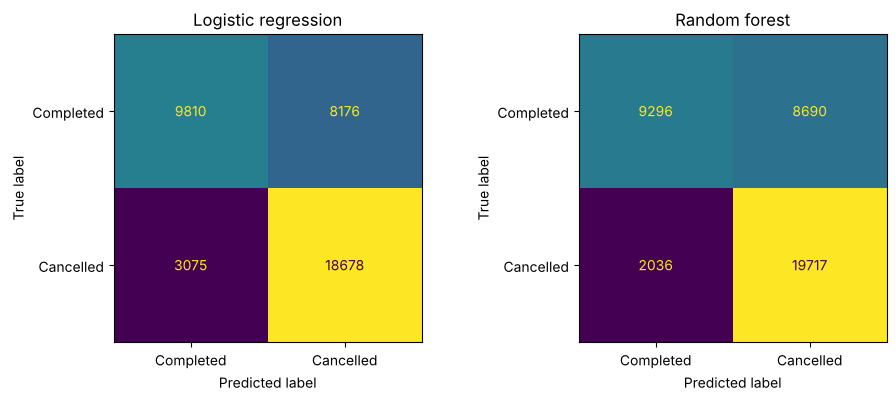

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, probability) in zip(axes, [("Logistic regression", logistic_probability), ("Random forest", forest_probability)]):
    ConfusionMatrixDisplay(
        confusion_matrix(test[TARGET], (probability >= 0.5).astype(int)),
        display_labels=["Completed", "Cancelled"],
    ).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(name)
plt.show()


**Confusion matrices.** Of the 21,753 cancelled orders in the test period, the logistic regression finds 18,678 and the random forest 19,717. The forest misses only 2,036 cancellations. The price is that both models flag almost half of the 17,986 completed orders as risky (8,176 and 8,690 false positives). With a threshold of 0.5, the models flag 68 % and 71 % of all orders as likely to be cancelled.

Whether this is acceptable depends on what a flagged order costs. If a flag only leads to a cheap confirmation SMS, a high recall is valuable. If it means a phone call or a delayed delivery, the store should raise the threshold and accept that fewer cancellations are found. The threshold of 0.5 is not tuned. In practice it should be chosen from the costs of the two types of error, using the development data.

## Error analysis

The models work less well on the test period than on the development period. To understand why, we look at the test period month by month, and at how much of the higher cancelled share is caused by the change in payment methods.

In [24]:
test_errors = test.assign(logistic=logistic_probability, forest=forest_probability)

monthly = test_errors.groupby(test_errors["created_at"].dt.to_period("M")).agg(
    orders=(TARGET, "size"),
    actual_cancelled=(TARGET, "mean"),
    logistic_predicted=("logistic", "mean"),
    forest_predicted=("forest", "mean"),
)
monthly["logistic_AUC"] = test_errors.groupby(test_errors["created_at"].dt.to_period("M")).apply(
    lambda month: roc_auc_score(month[TARGET], month["logistic"])
)
monthly["forest_AUC"] = test_errors.groupby(test_errors["created_at"].dt.to_period("M")).apply(
    lambda month: roc_auc_score(month[TARGET], month["forest"])
)
# How much of the higher cancelled share in the test period is due to the growth of bankalfalah?
not_bankalfalah = lambda part: part.loc[part["payment_group"] != "bankalfalah", TARGET].mean()
print(f"Cancelled share without bankalfalah: development {not_bankalfalah(development):.1%}, test {not_bankalfalah(test):.1%}")
monthly

Cancelled share without bankalfalah: development 40.0%, test 43.9%


,orders,actual_cancelled,logistic_predicted,forest_predicted,logistic_AUC,forest_AUC
created_at,,,,,,
2018-05,18088,0.510007,0.579521,0.608594,0.698646,0.754311
2018-06,8428,0.584718,0.586287,0.600502,0.859781,0.877746
2018-07,6454,0.627208,0.575072,0.608117,0.882102,0.895481
2018-08,6769,0.524745,0.555221,0.558509,0.790380,0.837213


**Findings.**

* **The higher cancelled share is mostly explained by the change in payment methods.** Without `bankalfalah`, the cancelled share is 40.0 % in the development period and 43.9 % in the test period, compared with 40.4 % and 54.7 % with it. The models capture most of this shift through the payment variables. Their average predicted probability in each test month (56–61 %) is close to the actual share (51–63 %), even though only 40 % of the training orders were cancelled.
* **May 2018 is clearly the weakest month** (AUC 0.699 for logistic regression and 0.754 for random forest). May is the busiest month in the test period (18,088 orders, almost half of the test set), it has a sales peak, and it is the month in which the store switched from `complete` to `received`. Both models also over-predict cancellations in May (58–61 % predicted vs 51 % actual). Busy campaign months seem to follow other patterns than normal months, and the status change may mean that orders are registered slightly differently.
* **June and July are predicted very well** (AUC 0.86–0.90), even better than in the cross-validation, and August lies in between (0.79–0.84).
* **The random forest is better than the logistic regression in every month**, with the largest difference in May (0.056) and the smallest in July (0.013). It handles the unusual month better.

The remaining errors are likely due to information the models do not have: the customer's history, stock-outs, delivery problems, failed online payments and the store's own checks of suspicious orders. Our interpretation also relies on `received` meaning the same as `complete`. We have not been able to confirm this beyond the clear switch in the monthly counts.

# Conclusion

## Summary

We have studied whether cancellations of orders in a Pakistani online store can be predicted from information that is available when the order is placed. The 584,524 order lines were checked, aggregated to 353,964 orders with a clear outcome (completed or cancelled), and split in time into a development period (July 2016 – April 2018) and a test period (May – August 2018) that was only used for the final evaluation. We fitted a logistic regression, evaluated with 5-fold cross-validation, and a random forest with parameters chosen on later months within the development period, and compared both with a simple payment method rule.

**Main results:**

1. **Payment method is the most important predictor.** Cash-on-delivery orders are cancelled far less often than orders paid online. Expensive orders are cancelled more often, and orders with discounts less often.
2. **The random forest predicts best.** On the test period it reaches an ROC-AUC of 0.827, against 0.792 for the logistic regression and 0.749 for the baseline. The logistic regression is easier to interpret, and both models point to the same variables.
3. **The models are useful, but far from perfect.** With a threshold of 0.5, the random forest finds 91 % of the cancellations, but also flags almost half of the completed orders.

**Lessons:**

* **Random cross-validation and OOB scores were too optimistic** (AUC 0.848 and 0.887) compared with the performance on later months. When data changes over time, the model should be evaluated on a later period, as in a real setting.
* **The data must be understood before it is modelled.** The switch from `complete` to `received` in May 2018, and the strong growth of one payment method in the test period, both changed the results considerably. Checking how the data is registered (one status and one `grand_total` per order, discounts per line) was necessary to build the order-level dataset correctly.

## Further work

With more time and resources, we would:

* **Use the customer's history.** The dataset contains `Customer ID`. The number of earlier orders, the customer's earlier cancelled share and how long the person has been a customer are likely to be strong predictors. To avoid leakage, they must be computed only from orders placed *before* the order being predicted.
* **Evaluate over time throughout.** Replace the random K-fold with a time-ordered cross-validation (for example `TimeSeriesSplit`), where every fold is trained on earlier months and evaluated on later ones, and retrain the model regularly (for example every month) on a moving window of recent data.
* **Choose the threshold from costs.** Together with the store, find the cost of a follow-up and of a cancellation, and choose the threshold that minimises the expected total cost.
* **Describe campaigns better.** Replace the month dummies with indicators for the actual campaign periods (such as 11.11 and other sales), which would also work in years the model has not seen.
* **Model more outcomes.** Include refunds as a third class in a multinomial model, so that the store can also predict returns after delivery.
* **Confirm the status definitions** with the data owner, especially whether `received` means exactly the same as `complete`.
* **Quantify the uncertainty** of the test results, for example with a formal test of the AUC difference between the two models, and use permutation importance to check the feature importance of the random forest.